# Modèle global de tarification automobile — version principale

**Version du 9 novembre 2026.**

La prime pure est le produit de la probabilité de sinistre et du montant moyen
conditionnel à un sinistre. Cette version conserve la gravité publiée de `main`
et importe la recette finale de fréquence de `projet-simplifie`.

- **Gravité :** XGBoost Gamma, contrat, prix et ancienneté du véhicule, classe géographique.
- **Fréquence :** 50 % logistique E et 50 % XGBoost recalibré ; 20 modèles XGBoost.
- **Prédiction finale :** `prime_predite = probabilite_sinistre × gravite_predite`.

Les origines exactes sont dans `integration_sources.json`. Les recherches et
versions antérieures sont conservées dans `archive/`.

## 1. Charger et vérifier la version actuelle

Ce notebook charge le modèle sauvegardé et reproduit les prédictions. Il ne
réentraîne pas les composants à chaque lecture. Le checksum est contrôlé avant
la désérialisation.

In [1]:
from pathlib import Path
import sys, json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from IPython.display import display, Image
cwd=Path.cwd().resolve()
ROOT=next(p for p in [cwd,*cwd.parents] if (p/'integration_sources.json').exists())
sys.path.insert(0,str(ROOT))
import run as app
model=app.load()
manifest=json.loads((ROOT/'models/global_model.json').read_text())
display(pd.Series({'version':manifest['version'],
                   'origine_gravite':manifest['sources']['severity_commit'],
                   'origine_frequence':manifest['sources']['frequency_commit'],
                   'gravite_reentrainee':manifest['severity']['refitted'],
                   'poids_xgboost_frequence':manifest['frequency']['blend_weight']},name='valeur').to_frame())
assert manifest['frequency']['fit_contracts']==50000
assert manifest['severity']['fit_positive_claims']==2917
assert manifest['severity']['refitted'] is True


/home/cytech/.local/lib/python3.12/site-packages/matplotlib/projections/__init__.py:63: UserWarning: Unable to import Axes3D. This may be due to multiple versions of Matplotlib being installed (e.g. as a system package and as a pip package). As a result, the 3D projection is not available.
  warnings.warn("Unable to import Axes3D. This may be due to multiple versions of "


,valeur
version,global-2026-11-09-full-data
origine_gravite,ea9fb85dc5ab0e6051de625667fb9422b2f2e22a
origine_frequence,682b3c5604b3fdf0ff9425a6c5b86c97df7640a1
gravite_reentrainee,True
poids_xgboost_frequence,0.5


## 2. Validation séparée de l’ajustement final

Le découpage par client utilise 39 964 contrats pour apprendre et 10 036 pour
valider (2 356 et 561 sinistres positifs). Les résultats ci-dessous proviennent
de cet ajustement 80/20, indépendant du modèle de production.

Après évaluation, la fréquence est réentraînée sur les 50 000 contrats et la
gravité sur les 2 917 sinistres positifs, avec les mêmes recettes et paramètres.
Le test Kaggle reste exclu de tout apprentissage. Les données ont déjà été
explorées ; cette validation ne constitue pas une cohorte externe neuve.

In [2]:
metrics=json.loads((ROOT/'reports/validation.json').read_text())
display(pd.Series(metrics,name='valeur').to_frame())
assert metrics['shared_clients']==0
assert metrics['training_contracts']==39964 and metrics['validation_contracts']==10036
assert metrics['validation_positive_claims']==561

,valeur
validation_contracts,10036.000000
validation_positive_claims,561.000000
training_contracts,39964.000000
training_positive_claims,2356.000000
shared_clients,0.000000
premium_rmse_euros,535.213925
premium_mae_euros,188.020429
premium_predicted_observed_ratio,1.031293
constant_premium_rmse_euros,539.119340
frequency_log_loss,0.206002


## 3. Prédire la prime pure et exporter la soumission

Les deux composantes utilisent exactement les mêmes lignes. Le fichier produit
est `outputs/submission.csv`, colonnes `index,pred`. Les composantes et prédictions
par contrat restent locales ; seules les statistiques agrégées sont affichées.

In [3]:
test=app.read(ROOT/'Data/test.csv')
components=app.write_predictions(model,test,ROOT/'outputs/submission.csv',ROOT/'outputs/test_components.csv')
assert len(components)==len(test)==50000
assert components['index'].tolist()==test['index'].tolist()
assert components['probabilite_sinistre'].between(0,1).all()
assert components['gravite_predite'].gt(0).all()
np.testing.assert_allclose(components['prime_predite'],components['probabilite_sinistre']*components['gravite_predite'],rtol=0,atol=0)
display(components.drop(columns='index').describe(percentiles=[.5,.9,.99]).T)

50,000 pure premiums written to /data/cours/Data Science/Project/TD-Tarification-automobile-par-Machine-Learning/outputs/submission.csv


,count,mean,std,min,50%,90%,99%,max
probabilite_sinistre,50000.0,0.058223,0.030158,0.002689,0.058658,0.096504,0.137143,0.227969
gravite_predite,50000.0,1656.210878,252.914750,1046.067993,1729.535034,1927.161011,2064.702637,2220.306396
prime_predite,50000.0,102.436626,61.082808,2.956282,103.944804,180.139741,260.587366,490.435640


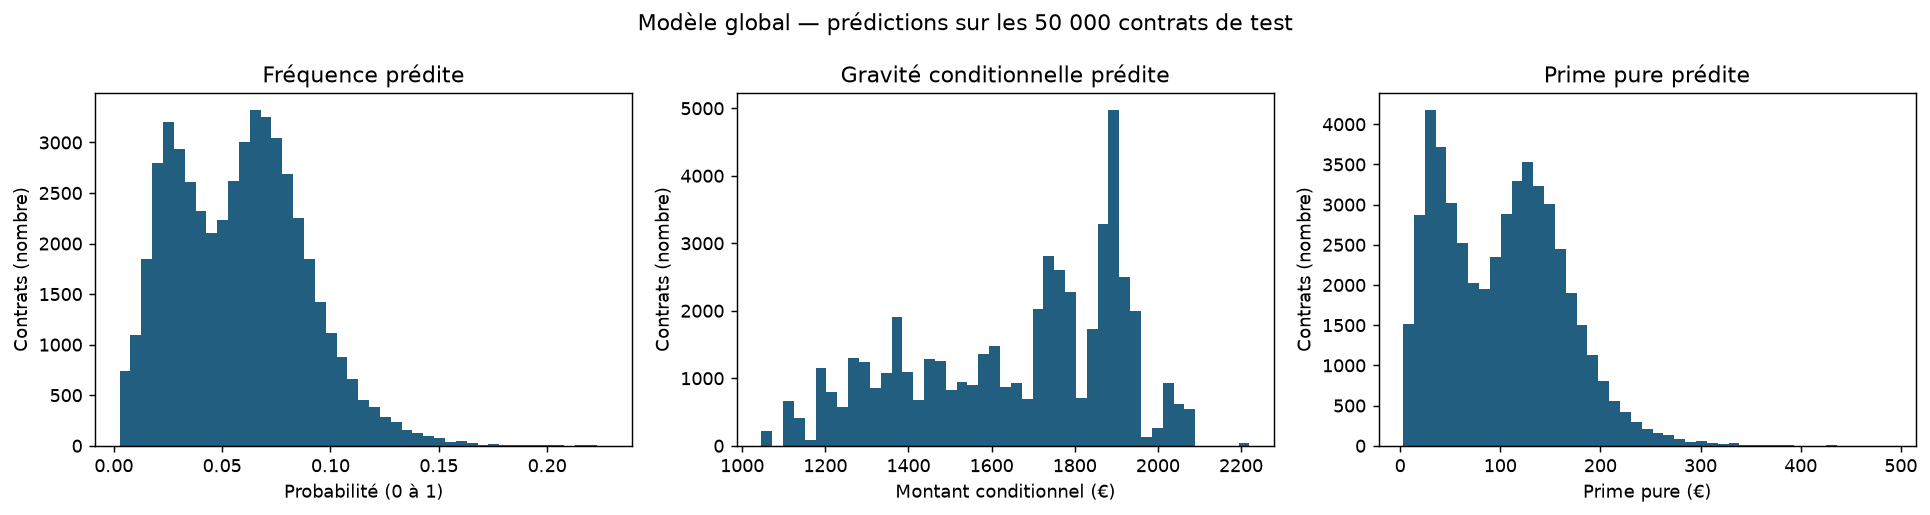

In [4]:
fig,axes=plt.subplots(1,3,figsize=(15,4))
for ax,col,title,unit in zip(axes,
    ['probabilite_sinistre','gravite_predite','prime_predite'],
    ['Fréquence prédite','Gravité conditionnelle prédite','Prime pure prédite'],
    ['Probabilité (0 à 1)','Montant conditionnel (€)','Prime pure (€)']):
    ax.hist(components[col],bins=45,color='#215e80')
    ax.set(title=title,xlabel=unit,ylabel='Contrats (nombre)')
fig.suptitle('Modèle global — prédictions sur les 50 000 contrats de test')
fig.tight_layout()
(ROOT/'reports').mkdir(exist_ok=True)
fig.savefig(ROOT/'reports/01_prediction_distributions.png',dpi=130,bbox_inches='tight')
display(Image(filename=str(ROOT/'reports/01_prediction_distributions.png')))
plt.close(fig)

## 4. Reproduction et anciennes versions

```sh
python run.py train --threads 2
python run.py verify
python run.py predict --input Data/test.csv --output outputs/submission.csv
python -m pytest
```

`train` évalue le couple sur le découpage 80/20, puis réentraîne séparément
les deux composants sur tout le train. La gravité garde ses quatre variables
et ses paramètres ; la fréquence garde la recette de `projet-simplifie`, les
quatre configurations, cinq graines et poids 50/50. Le runtime CPU commun
utilise XGBoost 3.0.2. Le manifeste distingue les effectifs de validation et
de production. Le notebook charge ce modèle final et régénère la soumission.

Les anciennes versions et recherches sont dans `archive/`.